# Tugas Praktikum
Jobsheet 4 - Klasterisasi

### Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons
from sklearn import metrics

sns.set()

## 1. Tugas K-Means
### Langkah 1 - Memuat Data
Dataset `Mall_Customers.csv`.

In [2]:
df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### Langkah 2 - Inspeksi Data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [4]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


### Langkah 3 - Pemilihan Fitur
Fitur yang tepat untuk segmentasi pelanggan adalah **Annual Income** dan **Spending Score** (2 fitur), karena keduanya menggambarkan kemampuan belanja dan perilaku belanja pelanggan.

In [5]:
# Pilih fitur numerik yang relevan untuk clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


### Langkah 4 - Visualisasi Sebaran Data

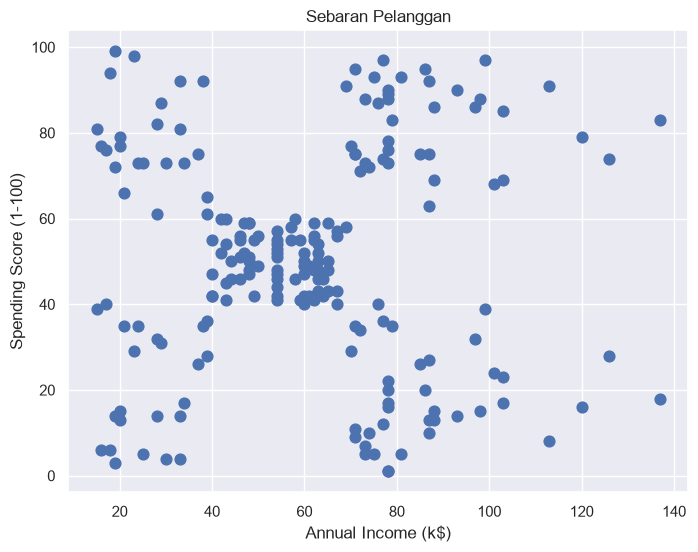

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=60)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Sebaran Pelanggan')
plt.show()

### Langkah 5 - Menentukan Jumlah k Terbaik (Metode Elbow)

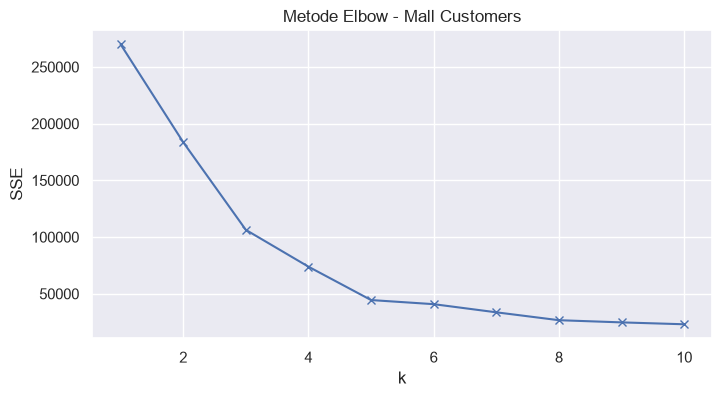

k=1; SSE=269981.28
k=2; SSE=183653.32894736843
k=3; SSE=106348.37306211119
k=4; SSE=73880.64496247195
k=5; SSE=44448.45544793371
k=6; SSE=40825.16946386946
k=7; SSE=33642.57922077922
k=8; SSE=26686.837785187785
k=9; SSE=24766.471609793443
k=10; SSE=23103.122085983916


In [7]:
sse = []
K = range(1, 11)
for k in K:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X)
    sse.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(K), sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Metode Elbow - Mall Customers')
plt.show()

for k, v in zip(K, sse):
    print(f'k={k}; SSE={v}')

### Langkah 6 - Membuat Model K-Means
Berdasarkan grafik elbow, titik siku berada di `k=5`, sehingga jumlah klaster terbaik adalah 5.

In [8]:
k_opt = 5
kmeans = KMeans(n_clusters=k_opt, random_state=42)
y_kmeans = kmeans.fit_predict(X)

### Langkah 7 - Visualisasi Hasil Klaster dan Centroid

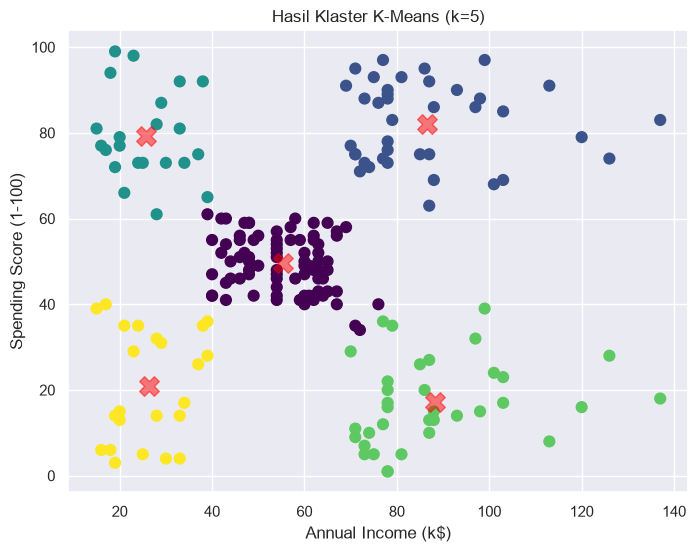

In [9]:
plt.figure(figsize=(8, 6))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y_kmeans, s=60, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5, marker='X')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title(f'Hasil Klaster K-Means (k={k_opt})')
plt.show()

### Langkah 8 - Interpretasi Tiap Klaster

In [10]:
df['Cluster'] = y_kmeans
df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].agg(['mean', 'count'])

Annual Income (k$)       Spending Score (1-100)      
                      mean count                   mean count
Cluster                                                      
0                55.296296    81              49.518519    81
1                86.538462    39              82.128205    39
2                25.727273    22              79.363636    22
3                88.200000    35              17.114286    35
4                26.304348    23              20.913043    23

## 2. Tugas DBSCAN
### Langkah 1 - Membuat Dataset make_moons dan Normalisasi

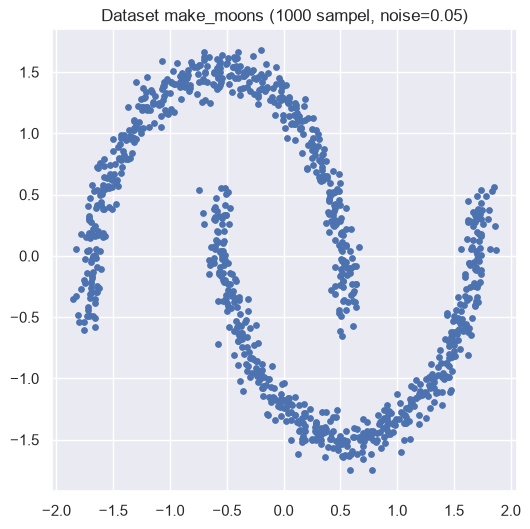

In [11]:
X_moons, y_moons = make_moons(n_samples=1000, noise=0.05, random_state=42)
X_moons = StandardScaler().fit_transform(X_moons)

plt.figure(figsize=(6, 6))
plt.scatter(X_moons[:, 0], X_moons[:, 1], s=15)
plt.title('Dataset make_moons (1000 sampel, noise=0.05)')
plt.show()

### Langkah 2 - Menjalankan DBSCAN (eps=0.2, min_samples=5)

In [12]:
db = DBSCAN(eps=0.2, min_samples=5).fit(X_moons)
labels = db.labels_

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 2
Estimated number of noise points: 0


### Langkah 3 - Evaluasi Kualitas Klasterisasi

In [13]:
print(f"Homogeneity: {metrics.homogeneity_score(y_moons, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(y_moons, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(y_moons, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(y_moons, labels):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(y_moons, labels):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X_moons, labels):.3f}")

Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index: 1.000
Adjusted Mutual Information: 1.000
Silhouette Coefficient: 0.391


### Langkah 4 - Visualisasi Hasil DBSCAN
Core sample = titik besar, non-core = titik kecil, noise = hitam.

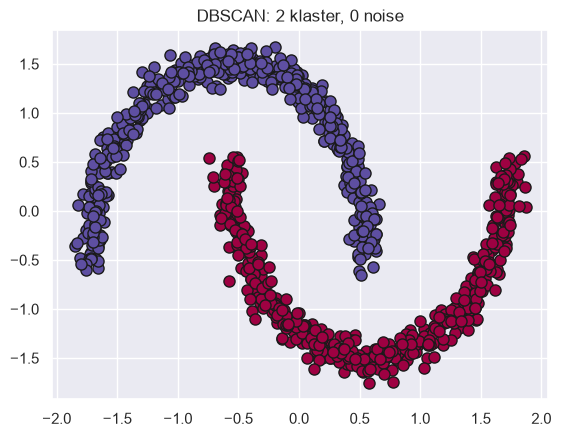

In [14]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    xy = X_moons[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col),
             markeredgecolor="k", markersize=8)

    xy = X_moons[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col),
             markeredgecolor="k", markersize=3)

plt.title(f"DBSCAN: {n_clusters_} klaster, {n_noise_} noise")
plt.show()

### Langkah 5 - Eksperimen eps dan min_samples
Mencatat perubahan jumlah klaster, noise, dan kualitas evaluasi untuk berbagai kombinasi parameter.

In [15]:
results = []
for eps in [0.05, 0.1, 0.3, 0.5]:
    for min_samples in [3, 10, 20]:
        db = DBSCAN(eps=eps, min_samples=min_samples).fit(X_moons)
        lbl = db.labels_
        n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_no = list(lbl).count(-1)
        try:
            sil = metrics.silhouette_score(X_moons, lbl)
        except Exception:
            sil = np.nan
        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'n_clusters': n_cl,
            'n_noise': n_no,
            'homogeneity': metrics.homogeneity_score(y_moons, lbl),
            'completeness': metrics.completeness_score(y_moons, lbl),
            'v_measure': metrics.v_measure_score(y_moons, lbl),
            'ari': metrics.adjusted_rand_score(y_moons, lbl),
            'ami': metrics.adjusted_mutual_info_score(y_moons, lbl),
            'silhouette': sil,
        })

res_df = pd.DataFrame(results)
res_df.round(3)

,eps,min_samples,n_clusters,n_noise,homogeneity,completeness,v_measure,ari,ami,silhouette
0,0.05,3,69,186,0.816,0.153,0.257,0.030,0.244,0.113
1,0.05,10,3,970,0.031,0.127,0.049,0.002,0.046,-0.294
2,0.05,20,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
3,0.10,3,2,14,0.986,0.903,0.943,0.972,0.943,0.252
4,0.10,10,7,57,0.943,0.410,0.571,0.523,0.570,0.162
5,0.10,20,6,850,0.154,0.155,0.155,0.017,0.151,-0.360
6,0.30,3,2,0,1.000,1.000,1.000,1.000,1.000,0.391
7,0.30,10,2,0,1.000,1.000,1.000,1.000,1.000,0.391
8,0.30,20,2,0,1.000,1.000,1.000,1.000,1.000,0.391
9,0.50,3,2,0,1.000,1.000,1.000,1.000,1.000,0.391


### Langkah 6 - Visualisasi Eksperimen

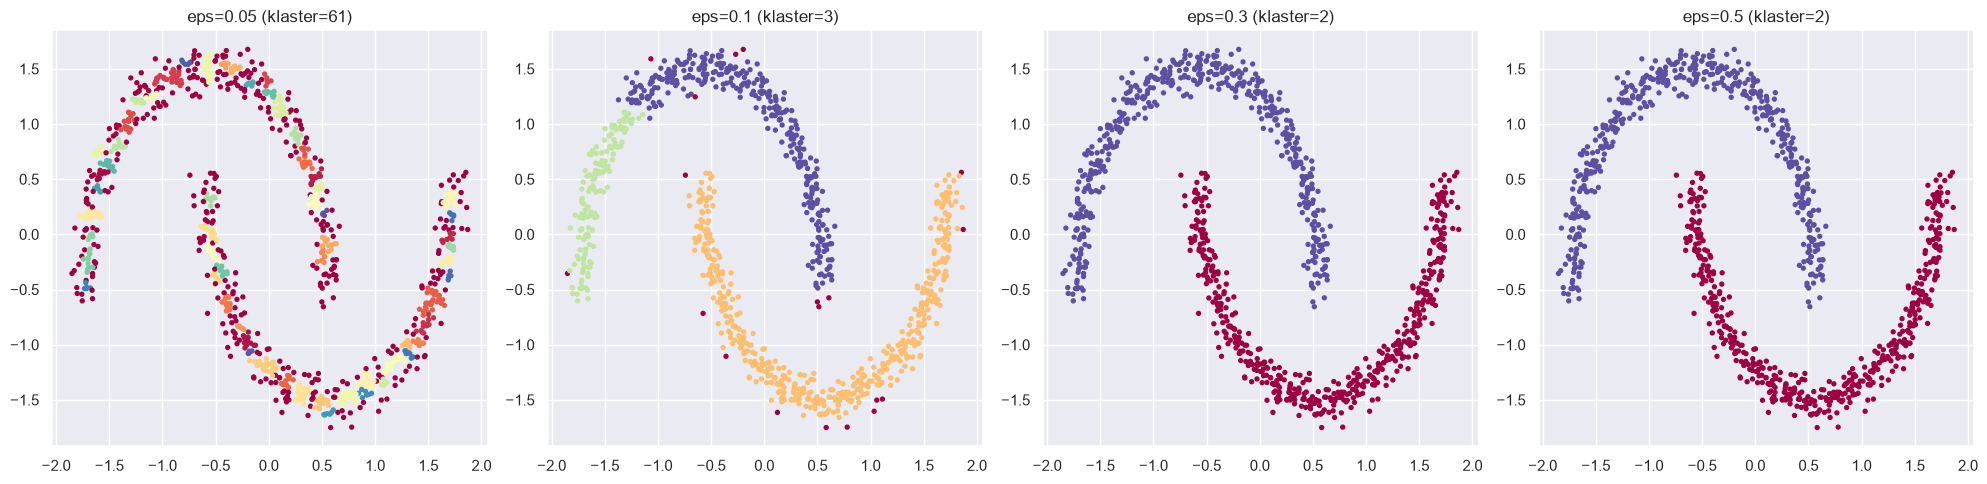

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, eps in zip(axes, [0.05, 0.1, 0.3, 0.5]):
    db = DBSCAN(eps=eps, min_samples=5).fit(X_moons)
    lbl = db.labels_
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=lbl, s=8, cmap='Spectral')
    n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
    ax.set_title(f'eps={eps} (klaster={n_cl})')
plt.tight_layout()
plt.show()

### Kesimpulan
* **K-Means (Mall Customers):** `k=5` menghasilkan segmentasi pelanggan berdasarkan pendapatan tahunan dan skor belanja.
* **DBSCAN (make_moons):** mampu memisahkan klaster non-linier yang gagal ditangani K-Means, dengan sebagian titik dikenali sebagai noise.
* Nilai `eps` yang terlalu kecil membuat banyak titik menjadi noise, sedangkan `eps` yang terlalu besar menggabungkan klaster yang seharusnya terpisah.